# Rosella sizing: H4 12S quadplane, SUAS 2027

This notebook sizes the lift system, the boom and the battery of Rosella for the least mission energy. The mission is the
flight path of Redback flight 00000171 under the SUAS 2027 rules. Each number in the code has units and a source.
`placeholder=True` marks a stand-in.

**Run:** do `python -m aeroplan setup AeroSandbox` one time. Copy the Proptimiser files of the lift and cruise blades into
`work/aerosandbox/redback/proptimiser` and `work/aerosandbox/currawong/proptimiser`. Run all cells in the kernel
"AeroPlan AeroSandbox" (about 7 min).

| Step | What it does |
|---|---|
| 1. Setup | Imports the model files |
| 2. Components | The boom tube, the lift system, the battery, the airframe, the fixed masses, the mission and the limits |
| 3. Fix | Fixes the bought tube and the boom layout. Prints the stand-ins |
| 4. Solve | Finds the most laps under the limits, rounds the battery to whole packs, then solves L0 to L4 |
| 5. Design | The design variables and the summary |
| 6. Limits | The active limits and their cost in Wh |
| 7. Mass and energy | The weight and energy bars, the battery through the mission, the energy timeline |
| 8. Blade | The lift blade against Jung et al. 2021 |
| 9. Boom vibration | f1 and f2 against the rotor speed |
| 10. Checks | The tube by hand, and the design with every value fixed |
| 11. Rules | The SUAS 2027 rules that are not limits |
| 12. Save | Writes `settings/rosella.json`. Then do `python -m aeroplan build rosella --author <name> --only AeroSandbox` |
| 13. Window | Change params and solve again (live notebook only) |

**Open items** (largest effect first):

1. Stand-in masses: avionics projects (0.75 kg budget), cables, landing gear, clamps, mounts. The retardant and the release are not in the list.
2. The delivery object box (11 x 9 x 4 in) does not fit the fuselage section (step 11).
3. The survey turn radius stand-in (40 m) is too small for the solved survey speed (step 11).
4. No wind. ISA sea-level air. No lap turns, no descent, no acceleration in the transitions.
5. `ground_time_s` (map and report after the landing) is 0. Time it in a rehearsal.
6. The lap speed sits on 1.3 Vs, so the energy follows the CL max stand-in.
7. The lift motor sits at its current limit. The rotor sits at its 26 in bound.
8. The wing structure is not checked for the boom loads. No fatigue or landing loads.
9. The boom density, G, knockdown, tip slope and resonance margin are stand-ins.
10. The solve does not trade the weight points (full points at 10 lb) against the lap points.


## 1. Setup

In [1]:
%load_ext autoreload
%autoreload 2
import sys

# Autoreload keeps an old module when one reload fails (for example a reload that comes before the module it imports).
# This loop reloads the model files in import order, so a re-run of this cell always uses the files on disk.
import importlib
for name in ("component", "mission", "model", "result", "optimise", "plot"):
    name = f"aeroplan.aerosandbox.{name}"
    if name in sys.modules:
        importlib.reload(sys.modules[name])

import math
import warnings
import pandas as pd
import matplotlib.pyplot as plt

from aeroplan import REPO_ROOT
from aeroplan.aerosandbox import plot
from aeroplan.aerosandbox.component import P, Airframe, Battery, Cables, Control, CruiseRotor, ESC, Fuselage, Material, Motor, PointMass, Rotor, Spec, Tube
from aeroplan.aerosandbox.mission import Mission
from aeroplan.aerosandbox.model import DESIGN_VARS, QuadplaneModel
from aeroplan.aerosandbox.optimise import evaluate, ladder, ladder_table

warnings.filterwarnings("ignore")
U = "user requirement 2026-10-17"
plot.style()
pd.set_option("display.float_format", lambda x: f"{x:.5g}")

## 2. Components
### 2.1 Boom tube


In [2]:
# The tube is a bought part (2.0 mm wall, E = 52 GPa). The fix in step 3 holds r_o and t.
# Resonance: f1 of a boom end stays under the band hover 1P - 20 %, so hover to full throttle is above the mode.
roll_wrapped = Material(
    "roll_wrapped",
    E_Pa=P(62.7e9, "Pa", "Rock West Composites SKU 45026, theoretical properties (classical lamination theory, reference only): 9.1 Msi tension; the page header shows 8.2 Msi, a conflict"),
    E_c_Pa=P(54.5e9, "Pa", "same page: 7.9 Msi compression"),
    density_kg_m3=P(1522.0, "kg/m3", "page gives 0.055 with no unit; read as lb/in3 (not confirmed)", placeholder=True),
    tensile_strength_Pa=P(372e6, "Pa", "same page: 54 ksi"),
    compressive_strength_Pa=P(359e6, "Pa", "same page: 52 ksi"),
    G_Pa=P(4.5e9, "Pa", "stand-in: typical 2x2 twill tube shear modulus; no maker figure found", placeholder=True),
    buckling_knockdown=P(0.5, "nd", "stand-in. NASA SP-8007 gives gamma = 1 - 0.901 (1 - exp(-phi)), phi = sqrt(R/t) / 29.8 (axial) and 0.731 in place of 0.901 for bending; the formula is from a search snippet, check it before use", placeholder=True))
bought_tube = roll_wrapped.with_E(52e9, "bought_tube")
bought_tube.params["E_Pa"].source = "user 2026-11-25: the bought lift boom tube, E = 52 GPa (the old note of 80 GPa was wrong). E_c keeps the ratio E_c / E of the roll-wrapped data"

boom = Tube(
    "boom",
    r_o=P(0.020, "m", "start value", free=True, lo=0.008, hi=0.045, scale=1e-2),
    t=P(0.0015, "m", "start value", free=True, lo=0.001, hi=0.005, scale=1e-3),
    y=P(0.65, "m", "start value", free=True, lo=0.35, hi=1.0, scale=0.65),
    dx=P(0.0, "m", "boom clamp shift from the wing root mid-chord (stand-in until the spar x is in the tree)", placeholder=True, free=True, lo=-0.35, hi=0.35, scale=0.1),
    a=P(0.50, "m", "start value", free=True, lo=0.25, hi=1.0, scale=0.5),
    overhang_m=P(0.06, "m", "stand-in: boom length beyond each hub", placeholder=True),
    mount_offset_m=P(0.02, "m", "stand-in: thrust line offset from the boom axis (torsion arm)", placeholder=True),
    clamp_kg=P(0.060, "kg", "stand-in: clamp at the wing, measure the part", placeholder=True),
    min_wall_m=P(0.001, "m", "user decision 2026-10-17: 1.0 mm minimum wall"),
    r_over_t_max=P(60.0, "nd", "stand-in: limit of the thin-wall tube formulas", placeholder=True),
    tip_slope_max_deg=P(2.0, "deg", "stand-in: boom tip slope at T_max", placeholder=True),
    resonance_margin=P(0.2, "nd", "stand-in: f1 stays outside 1P hover +/- 20 %. The principle (no coincidence of airframe and rotor frequency) is ISO 5109:2023. The margin is not from that text (not read)", placeholder=True),
    resonance_side=P("below", "", "user decision 2026-10-21: the boom must not be resonant at or near the hover rpm. below: f1 under the band, so hover to full throttle is above the mode. Burela and Sujit 2026 (arXiv 2607.22768, V.C) use the stricter f1 >= 1.5 x blade passing at peak rpm"),
    material=P("boom_material"))

### 2.2 Rotor, motor, ESC, battery, cables


In [3]:
# Lift blade: the Proptimiser design, the Jung 2021 T-motor shape fitted to the MAD FLUXER 22x6.6 table, scaled in radius.
# Masses: Bershadsky, Haviland, Johnson, AIAA 2016-0581. Pack: V = S OCV(SOC) - R_b I (Xing et al. 2014, Eq. 5).
# The MAX state and the cruise duty use the lowest SOC of the mission (1 - usable_fraction).
rotor = Rotor(
    "rotor",
    design=P("MAD_FLUXER_22x6_6_jung", "", "Proptimiser design, Jung 2021 T-motor shape fitted to the MAD FLUXER 22x6.6 maker table (Redback)"),
    design_aircraft=P("redback", "", "work folder that holds the design file and the state file"),
    reference_radius_m=P(0.2794, "m", "R_tip of the design file (D 559 mm). The scale s = R / 0.2794 gives other radii"),
    scale=P(1.0, "nd", "R / reference radius. Bounds: 406 mm to 660 mm diameter (16 in to 26 in). User decision 2026-10-17: 762 mm gained only 5.5 % energy for a 36 % extrapolation of the FLUXER blade",
            free=True, lo=0.2032 / 0.2794, hi=0.3302 / 0.2794, scale=1.0),
    cant=P(0.05, "rad", "tilt of each rotor about its radial axis; range 0 to 10 deg", free=True, lo=0.0, hi=math.radians(10.0), scale=0.1),
    blade_diameter_m=P(0.5588, "m", "MAD FLUXER 22x6.6: 22 in, converted to SI"),
    blade_pitch_m=P(0.16764, "m", "MAD FLUXER 22x6.6: 6.6 in, converted to SI. P/D is the pitch of an order sheet when the parts list gives none"),
    mass_kg=P(None), pitch_m=P(None),
    prop_g_a_in2=P(0.1207, "g/in2", "AIAA 2016-0581 Eq. 5, carbon (m = p1 (2R)^2 + p2 (2R) + p3; the text gives no p3, so p3 = 0; 2R in inch, from the figure axis)"),
    prop_g_b_in=P(-0.5122, "g/in", "same equation, p2"),
    tip_clearance_m=P(0.020, "m", "stand-in: gap between prop discs and the nearest structure", placeholder=True),
    tip_mach_max=P(0.65, "nd", "stand-in: tip Mach limit of the NeuralFoil sections", placeholder=True),
    coaxial_spacing_over_D=P(0.25, "nd", "Brazinskas et al. 2016: the 22 % loss holds for z/D > 0.25, so the pair is spaced at 0.25 D"),
    table_omega_rad_s=P([250.0, 388.0, 525.0, 663.0, 800.0], "rad/s", "numeric BEMT samples over the shaft speed range of the Opti variable"),
    table_scale=P([0.8, 1.0, 1.18], "nd", "geometric scale samples, inside the radius bounds"),
    table_v_x_m_s=P([0.0, 2.5], "m/s", "hover and the 2.5 m/s vertical climb of the mission"),
    table_poly_degree=P(3, "nd", "stand-in: lowest degree with a fit error under 1 % of CT; see the printed RMS", placeholder=True),
    momentum_omega_rad_s=P(435.0, "rad/s", "hover shaft speed of the base blade at about 37 N thrust (15 kg on 4 rotors); sets FM and the hover CT"),
    momentum_scale=P(1.0, "nd", "scale of the momentum constants"))

cruise_rotor = CruiseRotor(
    "cruise_rotor",
    design=P("Currawong_V1", "", "aircraft/currawong propeller installation 1.2.3.9 (motor X5220)"),
    design_aircraft=P("currawong", "", "work folder that holds the design file and the state file"),
    table_omega_rad_s=P([400.0, 500.0, 650.0, 800.0], "rad/s", "shaft speed range of the Opti variable of the cruise propeller"),
    table_J=P([0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9], "nd", "advance ratio samples"),
    table_fit_J_max=P(0.6, "nd", "the Currawong V1 blade gives CT below zero for J above 0.6; the fit covers the thrust range only"),
    table_poly_degree=P(4, "nd", "stand-in: lowest degree with a fit error under 1 % of CT", placeholder=True))

# User decision 2026-11-17: the lift propulsion system is fixed. The motor is the T-Motor VL6011 KV180 and the ESC is the
# T-Motor V80A 14S. The values come from the survey rows (maker store, read 2026-11-02).
VL6011 = "data/motor_survey.csv, row T-Motor VL6011 KV180 (maker store, read 2026-11-02)"
V80A = "data/esc_survey.csv, row T-Motor V80A 14S (maker store, read 2026-11-02)"
motor = Motor(
    "motor",
    part=P("T-Motor VL6011 KV180", "", VL6011),
    kv=P(180.0, "rpm/V", VL6011),
    q_cap=P((55.0 - 1.1) / (180.0 * 2.0 * math.pi / 60.0), "N*m", VL6011 + ": (Imax - I0) / Kv, with Imax 55 A and I0 1.1 A"),
    survey=P("data/motor_survey.csv", "", "sourced motor table (aeroplan/aerosandbox/data)"),
    kv_min=P(60.0, "rpm/V", "rows of the survey used by the fit"), kv_max=P(450.0, "rpm/V", "rows of the survey used by the fit"),
    mass_min_g=P(150.0, "g", "rows of the survey used by the fit"), mass_max_g=P(1600.0, "g", "rows of the survey used by the fit"),
    mass_kg=P(0.300, "kg", VL6011 + ": mass with the cable"), rm_ohm=P(0.080, "ohm", VL6011 + ": Rm at 25 C"),
    i0_A=P(1.1, "A", VL6011 + ": I0 at 10 V"),
    mount_kg=P(0.045, "kg", "stand-in: Redback motor mount mass, check against aircraft/redback", placeholder=True))

esc = ESC(
    "esc",
    survey=P("data/esc_survey.csv", "", "maker ESC rows of nine makers, see data/vendor_survey_SOURCE.md (aeroplan/aerosandbox/data); the fit uses the rows rated for the pack cell count"),
    peak_factor=P(1.2, "nd", "stand-in: ESC rated at 1.2 times the peak motor current", placeholder=True),
    re_ohm=P(0.020, "ohm", "stand-in: ESC resistance, inside the 9 to 45 mOhm range of AIAA 2016-0581 section II.B", placeholder=True),
    duty_max=P(0.95, "nd", "stand-in: ESC duty limit with a margin for the control", placeholder=True),
    part=P("T-Motor V80A 14S", "", V80A), current_cont_A=P(40.0, "A", V80A + ": continuous current"),
    mass_kg=P(0.078, "kg", V80A + ": mass without the wires"),
    current_A=P(80.0, "A", V80A + ": peak current for 10 s. The continuous rating is 40 A"))

battery = Battery(
    "battery",
    cells_s=P(12, "nd", "team decision: H4 12S"),
    cap_Ah=P(14.0, "A*h", "start value", free=True, lo=2.0, hi=60.0, scale=14.0),
    x_m=P(0.0, "m", "x of the pack centre; between the bay limits (stand-in: Currawong bay)", placeholder=True, free=True, lo=-0.45, hi=0.40, scale=0.1),
    cell_nominal_V=P(3.7, "V", "LiPo, Gens ace listing: 22.2 V for 6S"),
    ocv=P("data/ocv_lipo.csv", "", "stand-in: Aerolink OCV table of the Galeotti 2023 LiPo cells at 25 C (data/ocv_lipo_SOURCE.md), not the pack cell", placeholder=True),
    cell_resistance_mohm=P(5.0, "mohm", "stand-in: makers say 'low IR' only. aerolink flight battery fits R_b from a flight log", placeholder=True),
    c_rate_max=P(25.0, "1/h", "Gens ace / Tattu 4500 mAh 25C pack, maximum continuous"),
    usable_fraction=P(0.90, "nd", "user decision 2026-11-25: 10 % SOC floor (was 20 %), the lowest row of the OCV table"),
    eq4_p1=P(0.026373, "g/(mAh)", "AIAA 2016-0581 Eq. 4: m = (p1 s + p2) C, g, C in mAh"),
    eq4_p2=P(2.0499e-05, "g/(mAh)", "AIAA 2016-0581 Eq. 4"),
    cal_cells_s=P(6, "nd", "calibration pack: Gens ace / Tattu 4500 mAh 22.2 V 25C 6S1P"),
    cal_capacity_Ah=P(4.5, "A*h", "calibration pack capacity"),
    cal_mass_kg=P(0.631, "kg", "Propalyser component for the NXE 6S 4500 pack (631 g, 99.9 Wh). The Gens ace listing says 610 g"),
    mass_kg=P(None))

cables = Cables(
    "cables",
    current_density_A_m2=P(10.0e6, "A/m2", "stand-in: 10 A/mm2 for short silicone leads in free air; ampacity table not found", placeholder=True),
    insulation_factor=P(1.4, "nd", "stand-in: mass of insulation as a fraction on the copper mass", placeholder=True),
    run_extra_m=P(0.15, "m", "stand-in: extra lead length for routing at each end of the run", placeholder=True))

### 2.3 Airframe, fuselage, fixed masses


In [4]:
# Wing, tail and tail boom: aircraft/currawong. CG = NP - SM x MAC. The new fuselage is a superellipse body.
airframe = Airframe(
    "airframe",
    base=P("currawong", "", "wing, htail, fin and tail boom come from aircraft/currawong"),
    static_margin_target=P(0.10, "nd", "user decision 2026-10-17: CG = NP - SM x MAC; 10 % MAC is the design choice", placeholder=True),
    cg_nose_prop_m=P(0.800, "m", "user measurement 2026-10-17: CG about 0.800 m behind the nose propeller hub (estimate; the CG is a design output)"))

fuselage = Fuselage(
    "fuselage",
    stations=P(21, "nd", "frames of the body"),
    width_m=P(0.24, "m", "stand-in: the Currawong V1 maximum width (aircraft/currawong fuselage frames); size the bay for the real battery", placeholder=True),
    height_m=P(0.18, "m", "stand-in: the Currawong V1 maximum height", placeholder=True),
    superellipse_n=P(2.5, "nd", "section shape exponent"),
    z_centre_m=P(0.02, "m", "axis height of the body"),
    nose_behind_hub_m=P(0.07, "m", "Currawong V1 is 0.07 m behind the nose propeller hub at the nose"),
    x_tail_m=P(0.561261779785036, "m", "user 2026-10-21: the pod tail end stays 561 mm aft of the wing root leading edge (the start of the old tail boom). The new tail boom starts inside the pod, so the pod end no longer follows the boom"),
    bay_x_m=P([-0.45, 0.40], "m", "stand-in: the battery centre can sit between these x (Currawong bay)", placeholder=True),
    battery_Wh_per_L=P(330.0, "Wh/L", "stand-in: LiPo pack energy density for the bay check", placeholder=True))

avionics = PointMass("avionics", projects_mass_kg=P(0.75, "kg", "user 2026-11-25: mass budget of the avionics projects (not weighed). The flight avionics is the Currawong AVIONICS-REST mass (0.609 kg, weighed)", placeholder=True),
                     power_W=P(25.0, "W", "stand-in: flight avionics, avionics projects and servos", placeholder=True))
landing_gear = PointMass("landing_gear", mass_kg=P(0.60, "kg", "stand-in: VTOL skids; the Currawong gear is 1.32 kg", placeholder=True),
                         x_m=P(0.16, "m", "Currawong gear x"), z_m=P(-0.10, "m", "gear height"))
LB = 0.45359237                                       # kg per lb (exact, NIST SP 811)
cargo = PointMass("cargo", mass_kg=P(3.0 * LB, "kg", "SUAS 2027 Primer and Task Ideas, p. 18 (Task 5): one delivery object, up to 3 lb, inside 11 x 9 x 4 in, not disclosed until the mission. Sized at the maximum. Released at the end of the deployment hover"),
                  x_from_cg=P(0.0, "m", "cargo sits at the CG"))

### 2.4 Mission, limits, control, cruise aerodynamics


In [5]:
mission = Mission(
    "mission",
    climb_height_m=P(93.0, "m", "Redback flight 00000171 (2026-09-15), work/ardupilot/redback/00000171.BIN"),
    climb_rate_m_s=P(2.6, "m/s", "same flight"),
    transit_m=P(656.0, "m", "same flight"),
    lap_length_m=P(3370.0, "m", "same flight, 10 endurance laps in place of 1"),
    lap_count=P(10, "nd", "SUAS 2027 Primer, p. 14: up to 10 waypoint laps. Section 4 lowers it to the most laps that fit"),
    rtl_m=P(660.0, "m", "same flight"),
    survey_lines=P(6, "nd", "same flight"), survey_line_length_m=P(259.0, "m", "same flight"),
    survey_turn_bank_deg=P(30.0, "deg", "same flight"),
    deployment_hover_s=P(60.0, "s", "Mk4 sheet for the deployment hover"),
    reserve_hover_s=P(300.0, "s", U + " (5 min reserve hover battery)"),
    vtol_climb_m=P(30.0, "m", "vertical take-off climb height"), vtol_climb_rate_m_s=P(2.5, "m/s", "vertical climb rate"),
    vtol_descent_rate_m_s=P(1.5, "m/s", "vertical descent rate"), transition_s=P(15.0, "s", "transition time, each way"),
    mission_clock_s=P(45.0 * 60.0, "s", "SUAS 2027 Primer, p. 14 and p. 17: 45 min mission clock; the map and the JSON report are due by USB inside it"),
    ground_time_s=P(0.0, "s", "stand-in: the time to make the map and the report after the landing and to hand over the USB. Not measured: time it in a rehearsal", placeholder=True))

limits = Spec(
    "limits",
    uas_mass_kg=P(35.0 * LB, "kg", "SUAS 2027 Primer, p. 16 (Task 3): UAS weight 35 lb or less (max weight cap); the weight does not include the delivery object"),
    thrust_to_weight=P(2.3, "nd", U + " (hover thrust at full throttle over MTOW)"),
    load_factor=P(3.0, "nd", U + " (3 g boom strength)"),
    safety_factor=P(1.5, "nd", "stand-in: the usual factor for ultimate load on a composite part", placeholder=True))

control = Control(
    "control",
    bandwidth_rad_s=P(2.0, "rad/s", "ADS-33E-PRF, 'all other MTEs and divided attention', Level 1 (Ivler et al., Toward a UAS Handling Qualities Specification, Methodology)"),
    bandwidth_length_m=P(11.9, "m", "derived: 1.8 ft x 21.7 = 39 ft (Ivler et al., Table 2 and Eq. 1)"),
    amplitude_rad=P(0.1745, "rad", "stand-in: 10 deg, the heading tolerance of the Ivler MTE tables. Not a figure for roll or pitch", placeholder=True),
    margin=P(1.2, "nd", "stand-in: factor on the required angular acceleration", placeholder=True),
    yaw_rad_s2=P(1.5, "rad/s2", "user decision 2026-10-17 after a sweep of 0.5 to 3.0 (cost 2 Wh above 1.0, cant 5.6 deg). No yaw figure in Ivler et al.", placeholder=True),
    idle_thrust_fraction=P(0.15, "nd", "stand-in: lowest rotor thrust in flight as a fraction of the hover thrust", placeholder=True),
    k_int=P(1.28, "nd", "derived: 1 / (1 - 0.22), the power factor at equal thrust (Brazinskas et al. 2016, abstract: 22 % loss for torque-balanced coaxial at z/D > 0.25). Leishman and Syal case 4b gives 1.26"))

cruise_aero = Spec(
    "cruise_aero",
    boom_cf=P(0.0045, "nd", "stand-in: skin friction of a smooth tube at Re about 1e6 (flat plate, turbulent)", placeholder=True),
    boom_form_factor=P(1.2, "nd", "stand-in: Hoerner form factor of a cylinder along the flow", placeholder=True),
    nacelle_cda_m2=P(0.0010, "m2", "stand-in: drag area of one motor and mount in the flow", placeholder=True),
    stopped_prop_cda_per_r2=P(0.01, "nd", "stand-in: drag area of a stopped prop aligned with the flow, per m2 of R squared", placeholder=True),
    cl_max_usable_factor=P(0.85, "nd", "stand-in: factor on the AeroBuildup CL at 12 deg", placeholder=True),
    stall_margin=P(1.3, "nd", "1.3 Vs (user plan)"),
    map_turn_radius_m=P(40.0, "m", "stand-in: 30 deg bank turns at 15 m/s", placeholder=True))

### 2.5 Model


In [6]:
model = QuadplaneModel(
    "rosella",
    {"limits": limits, "mission": mission, "airframe": airframe, "fuselage": fuselage, "boom_material": bought_tube,
     "boom": boom, "rotor": rotor, "cruise_rotor": cruise_rotor, "motor": motor, "esc": esc, "battery": battery,
     "cables": cables, "avionics": avionics, "landing_gear": landing_gear, "cargo": cargo,
     "cruise_aero": cruise_aero, "control": control},
    layout="H4")

## 3. Fix the bought tube and the boom layout


In [7]:
model.fix(boom__r_o=0.0127, boom__t=0.002)
model.fix(boom__y=0.55, boom__a=0.60)
model.c["boom"].p("y").source = "user 2026-11-09: boom spacing 1100 mm (y = 550 mm), so that the lift rotor discs clear the cruise propeller"
model.c["boom"].p("a").source = "user 2026-11-09: hub spacing 1200 mm (a = 600 mm), so that the lift rotor discs clear the cruise propeller"
model.c["boom"].p("r_o").source = "user 2026-10-21: the lift boom tube is the tail boom tube, 25.4 mm outer diameter (outer radius 12.7 mm)"
model.c["boom"].p("t").source = "user 2026-11-25: the lift boom tube is the tail boom tube, wall 2.0 mm (inner diameter 21.4 mm). The old note of 23.4 mm (wall 1.0 mm) was wrong"
free = [(ck, pk, p) for ck, pk, p in model.params() if p.free]
pd.DataFrame([{"param": f"{ck}.{pk}", "start": p.value, "lo": p.lo, "hi": p.hi, "units": p.units} for ck, pk, p in free]).set_index("param")

,start,lo,hi,units
param,,,,
boom.dx,0,-0.35,0.35,m
rotor.scale,1,0.72727,1.1818,nd
rotor.cant,0.05,0,0.17453,rad
battery.cap_Ah,14,2,60,A*h
battery.x_m,0,-0.45,0.4,m


In [8]:
ph = model.placeholders()
print(f"{len(ph)} params are stand-ins (placeholder=True). The ones that set the result:")
for k in ("boom_material.density_kg_m3", "boom_material.buckling_knockdown", "boom.resonance_margin", "boom.clamp_kg",
          "boom.overhang_m", "motor.mount_kg", "control.margin", "control.yaw_rad_s2", "esc.peak_factor"):
    print("  ", k, "->", model.c[k.split(".")[0]].params[k.split(".")[1]].value)

44 params are stand-ins (placeholder=True). The ones that set the result:
   boom_material.density_kg_m3 -> 1522.0
   boom_material.buckling_knockdown -> 0.5
   boom.resonance_margin -> 0.2
   boom.clamp_kg -> 0.06
   boom.overhang_m -> 0.06
   motor.mount_kg -> 0.045
   control.margin -> 1.2
   control.yaw_rad_s2 -> 1.5
   esc.peak_factor -> 1.2


## 4. Solve


,level,mass less cargo [kg],energy [Wh],battery [Ah],worst limit
laps,,,,,
10,L1,16.183,433.17,10.478,uas_mass_kg -1.9 %
9,L1,16.031,411.53,9.9543,uas_mass_kg -1.0 %
8,L1,15.882,390.13,9.4368,uas_mass_kg -0.0 %
7,L2,15.755,364.4,8.8144,energy_Wh -0.0 %


8.81 Ah -> 4 packs, 9.0 Ah, 2.524 kg


,level,mass less cargo [kg],energy [Wh],battery [Ah],worst limit
laps,,,,,
10,L0,15.295,406.27,9,energy_Wh -9.2 %
9,L0,15.298,389.46,9,energy_Wh -4.7 %
8,L0,15.301,372.67,9,energy_Wh -0.2 %
7,L2,15.809,365.67,9,motor_current_front +0.0 %


7 laps fit.
Ladder H4_12S
level status            s    M kg    E Wh   D mm     kv  worst 5 constraints (margin)
L0    ok              3.0   16.67     356    660    180  stall_margin_lap +0.022, uas_mass_kg +0.036, energy_Wh +0.043, stall_margin_map +0.048, tip_mach_MAX_f +0.248
L1    ok              4.5   17.17     365    660    180  motor_current_front +0.000, motor_current_rear +0.000, uas_mass_kg +0.004, stall_margin_lap +0.007, energy_Wh +0.018
L2    ok              1.0   17.17     366    660    180  motor_current_front +0.000, motor_current_rear +0.000, control_yaw_rad_s2 +0.000, uas_mass_kg +0.004, stall_margin_lap +0.007
L3    ok             20.3   17.17     366    660    180  motor_current_front +0.000, motor_current_rear +0.000, control_yaw_rad_s2 +0.000, uas_mass_kg +0.004, stall_margin_lap +0.007
L4    ok            123.8   17.17     366    660    180  control_yaw_rad_s2 -0.000, motor_current_front -0.000, motor_current_rear -0.000, uas_mass_kg +0.004, stall_margin_lap +0.00

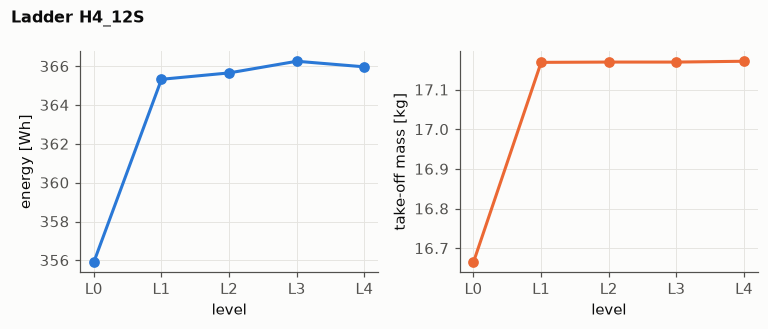

In [9]:
OUT = REPO_ROOT / "work" / "aerosandbox" / "rosella" / "notebook_ladder"
laps, bat = model.c["mission"].p("lap_count"), model.c["battery"]
LAPS_MAX = int(laps.value)                              # SUAS 2027: 10 laps at most


def most_laps(levels="L0..L2"):
    """The most laps that fit at `levels` (from LAPS_MAX down). L0 has no motor limits: read L2 or L4."""
    rows = []
    for k in range(LAPS_MAX, 0, -1):
        laps.value = k
        r = ladder(model, levels, out=OUT, multistart=5, log=lambda s: None)
        last = max(r["reports"])
        rp = r["reports"][last]
        worst = min(rp.enabled().items(), key=lambda kv: kv[1]["margin"])
        rows.append({"laps": k, "level": last, "mass less cargo [kg]": rp.mass_kg - model.c["cargo"]["mass_kg"],
                     "energy [Wh]": rp.energy_Wh, "battery [Ah]": rp.design["cap_Ah"],
                     "worst limit": f"{worst[0]} {100 * worst[1]['margin']:+.1f} %"})
        if last == levels[-2:] and rp.ok:
            display(pd.DataFrame(rows).set_index("laps"))
            return k, rp
    raise RuntimeError("no lap count fits")


# 4a. Free capacity: the most laps, and the capacity they need.
n_laps, rp = most_laps()
# 4b. Whole packs: the team packs are 6S 4500 mAh (22.2 V, 99.9 Wh). 12S puts two in series, so the capacity steps by one
#     string (4.5 Ah, two packs). Round to the nearest string. The pack mass is the weighed pack, not Eq. 4.
per_string = int(bat["cells_s"]) // int(bat["cal_cells_s"])
strings = max(1, round(rp.design["cap_Ah"] / bat["cal_capacity_Ah"]))
packs = strings * per_string
model.fix(battery__cap_Ah=strings * bat["cal_capacity_Ah"])
bat.p("cap_Ah").source = (f"user 2026-11-25: whole 6S 4500 mAh packs, {strings} string(s) of {per_string} in series "
                          f"({packs} packs), the nearest to the {rp.design['cap_Ah']:.2f} Ah of the free solve")
bat.params["mass_kg"] = P(packs * bat["cal_mass_kg"], "kg", f"{packs} x {bat['cal_mass_kg']} kg, the calibration pack mass (cal_mass_kg)")
print(f"{rp.design['cap_Ah']:.2f} Ah -> {packs} packs, {strings * bat['cal_capacity_Ah']:.1f} Ah, {bat['mass_kg']:.3f} kg")
# 4c. The most laps with the whole packs.
n_laps, rp = most_laps()
# 4d. L0 to L4 at that count. One lap less if L4 does not fit.
while True:
    laps.value = n_laps
    run = ladder(model, "L0..L4", out=OUT, multistart=5, log=lambda s: None)
    if "L4" in run["reports"] and run["reports"]["L4"].ok:
        break
    n_laps -= 1
    assert n_laps >= 1, "no lap count fits at L4"
laps.source = (f"SUAS 2027 Primer, p. 14: up to 10 waypoint laps. {n_laps} laps is the most that fit under the limits "
               "(lap sweep of rosella_sizing.ipynb, step 4)")
print(f"{n_laps} laps fit.")
print(ladder_table(run))
res = run["reports"]["L4"]
assert res.ok, "L4 did not converge"
plot.ladder_chart(run);


## 5. The design

In [10]:
d = res.design
names = {"t_boom": "boom wall", "r_boom": "boom outer radius", "y_b": "boom lateral position", "dx": "clamp shift from wing mid-chord",
         "a": "hub distance from the clamp", "scale": "rotor scale R / 279.4 mm", "kv": "motor kV", "q_cap": "motor peak torque",
         "cant": "rotor cant", "cap_Ah": "battery capacity", "x_batt": "battery x"}
units = {"t_boom": "mm", "r_boom": "mm", "y_b": "m", "dx": "m", "a": "m", "scale": "", "kv": "rpm/V", "q_cap": "N m", "cant": "deg",
         "cap_Ah": "A h", "x_batt": "m"}
conv = {"t_boom": 1e3, "r_boom": 1e3, "cant": 180 / math.pi}
rows = []
for k, (ck, pk) in DESIGN_VARS.items():
    p = model.c[ck].params[pk]
    rows.append({"variable": names[k], "value": d[k] * conv.get(k, 1.0), "unit": units[k], "state": "free" if p.free else "fixed"})
pd.DataFrame(rows).set_index("variable")

,value,unit,state
variable,,,
boom wall,2,mm,fixed
boom outer radius,12.7,mm,fixed
boom lateral position,0.55,m,fixed
clamp shift from wing mid-chord,-0.056276,m,free
hub distance from the clamp,0.6,m,fixed
rotor scale R / 279.4 mm,1.1818,,free
motor kV,180,rpm/V,fixed
motor peak torque,2.8595,N m,fixed
rotor cant,2.4655,deg,free


In [11]:
n = res["names"]
summary = pd.Series({
    "take-off mass [kg]": res.mass_kg, "mission energy [Wh]": res.energy_Wh, "nominal battery energy [Wh]": res["energy_nominal_Wh"],
    "rotor diameter [mm]": 1000 * res["D_m"], "motor mass [g]": 1000 * n["m_motor"], "propeller mass [g]": 1000 * n["m_prop"],
    "ESC mass [g]": 1000 * n["m_esc"], "battery mass [kg]": n["m_batt"], "peak motor current [A]": n["I_pk"],
    "boom length each [mm]": 1000 * n["L_boom"], "boom mass each [g]": 500 * n["m_boom"],
    "hover speed [rpm]": res["rotors"]["H_TO_f"]["rpm"], "boom f1 [Hz]": res["f1_Hz"], "hover 1P [Hz]": res["f_hover_1P_Hz"],
    "lap speed [m/s]": n["V_lap"], "survey speed [m/s]": n["V_map"], "stall speed [m/s]": n["Vs"]}, name="H4 12S, bought tube")
summary.to_frame()

,"H4 12S, bought tube"
take-off mass [kg],17.172
mission energy [Wh],365.98
nominal battery energy [Wh],399.6
rotor diameter [mm],660.4
motor mass [g],300
propeller mass [g],68.276
ESC mass [g],78
battery mass [kg],2.524
peak motor current [A],53.997
boom length each [mm],1320


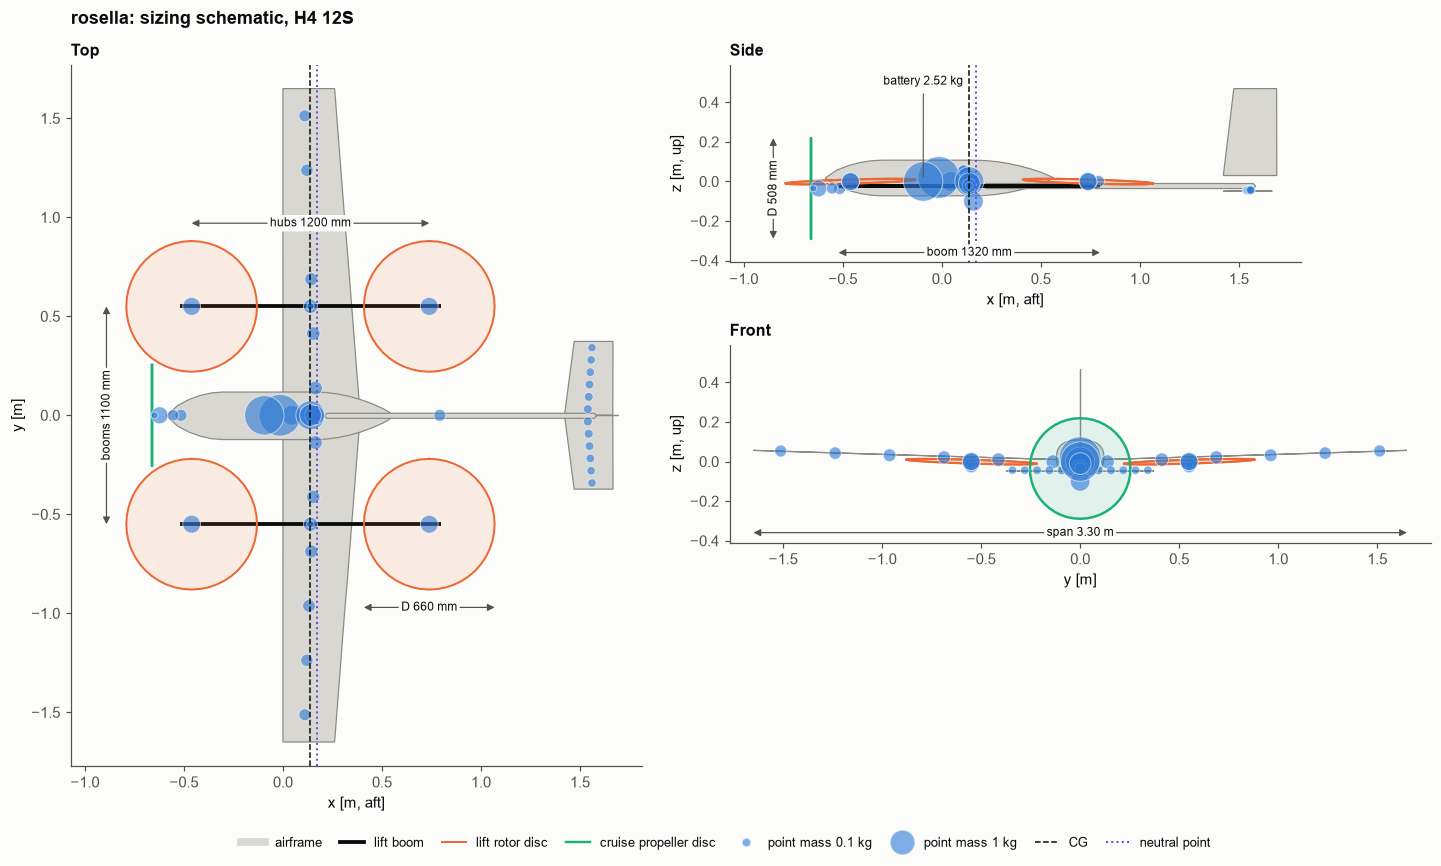

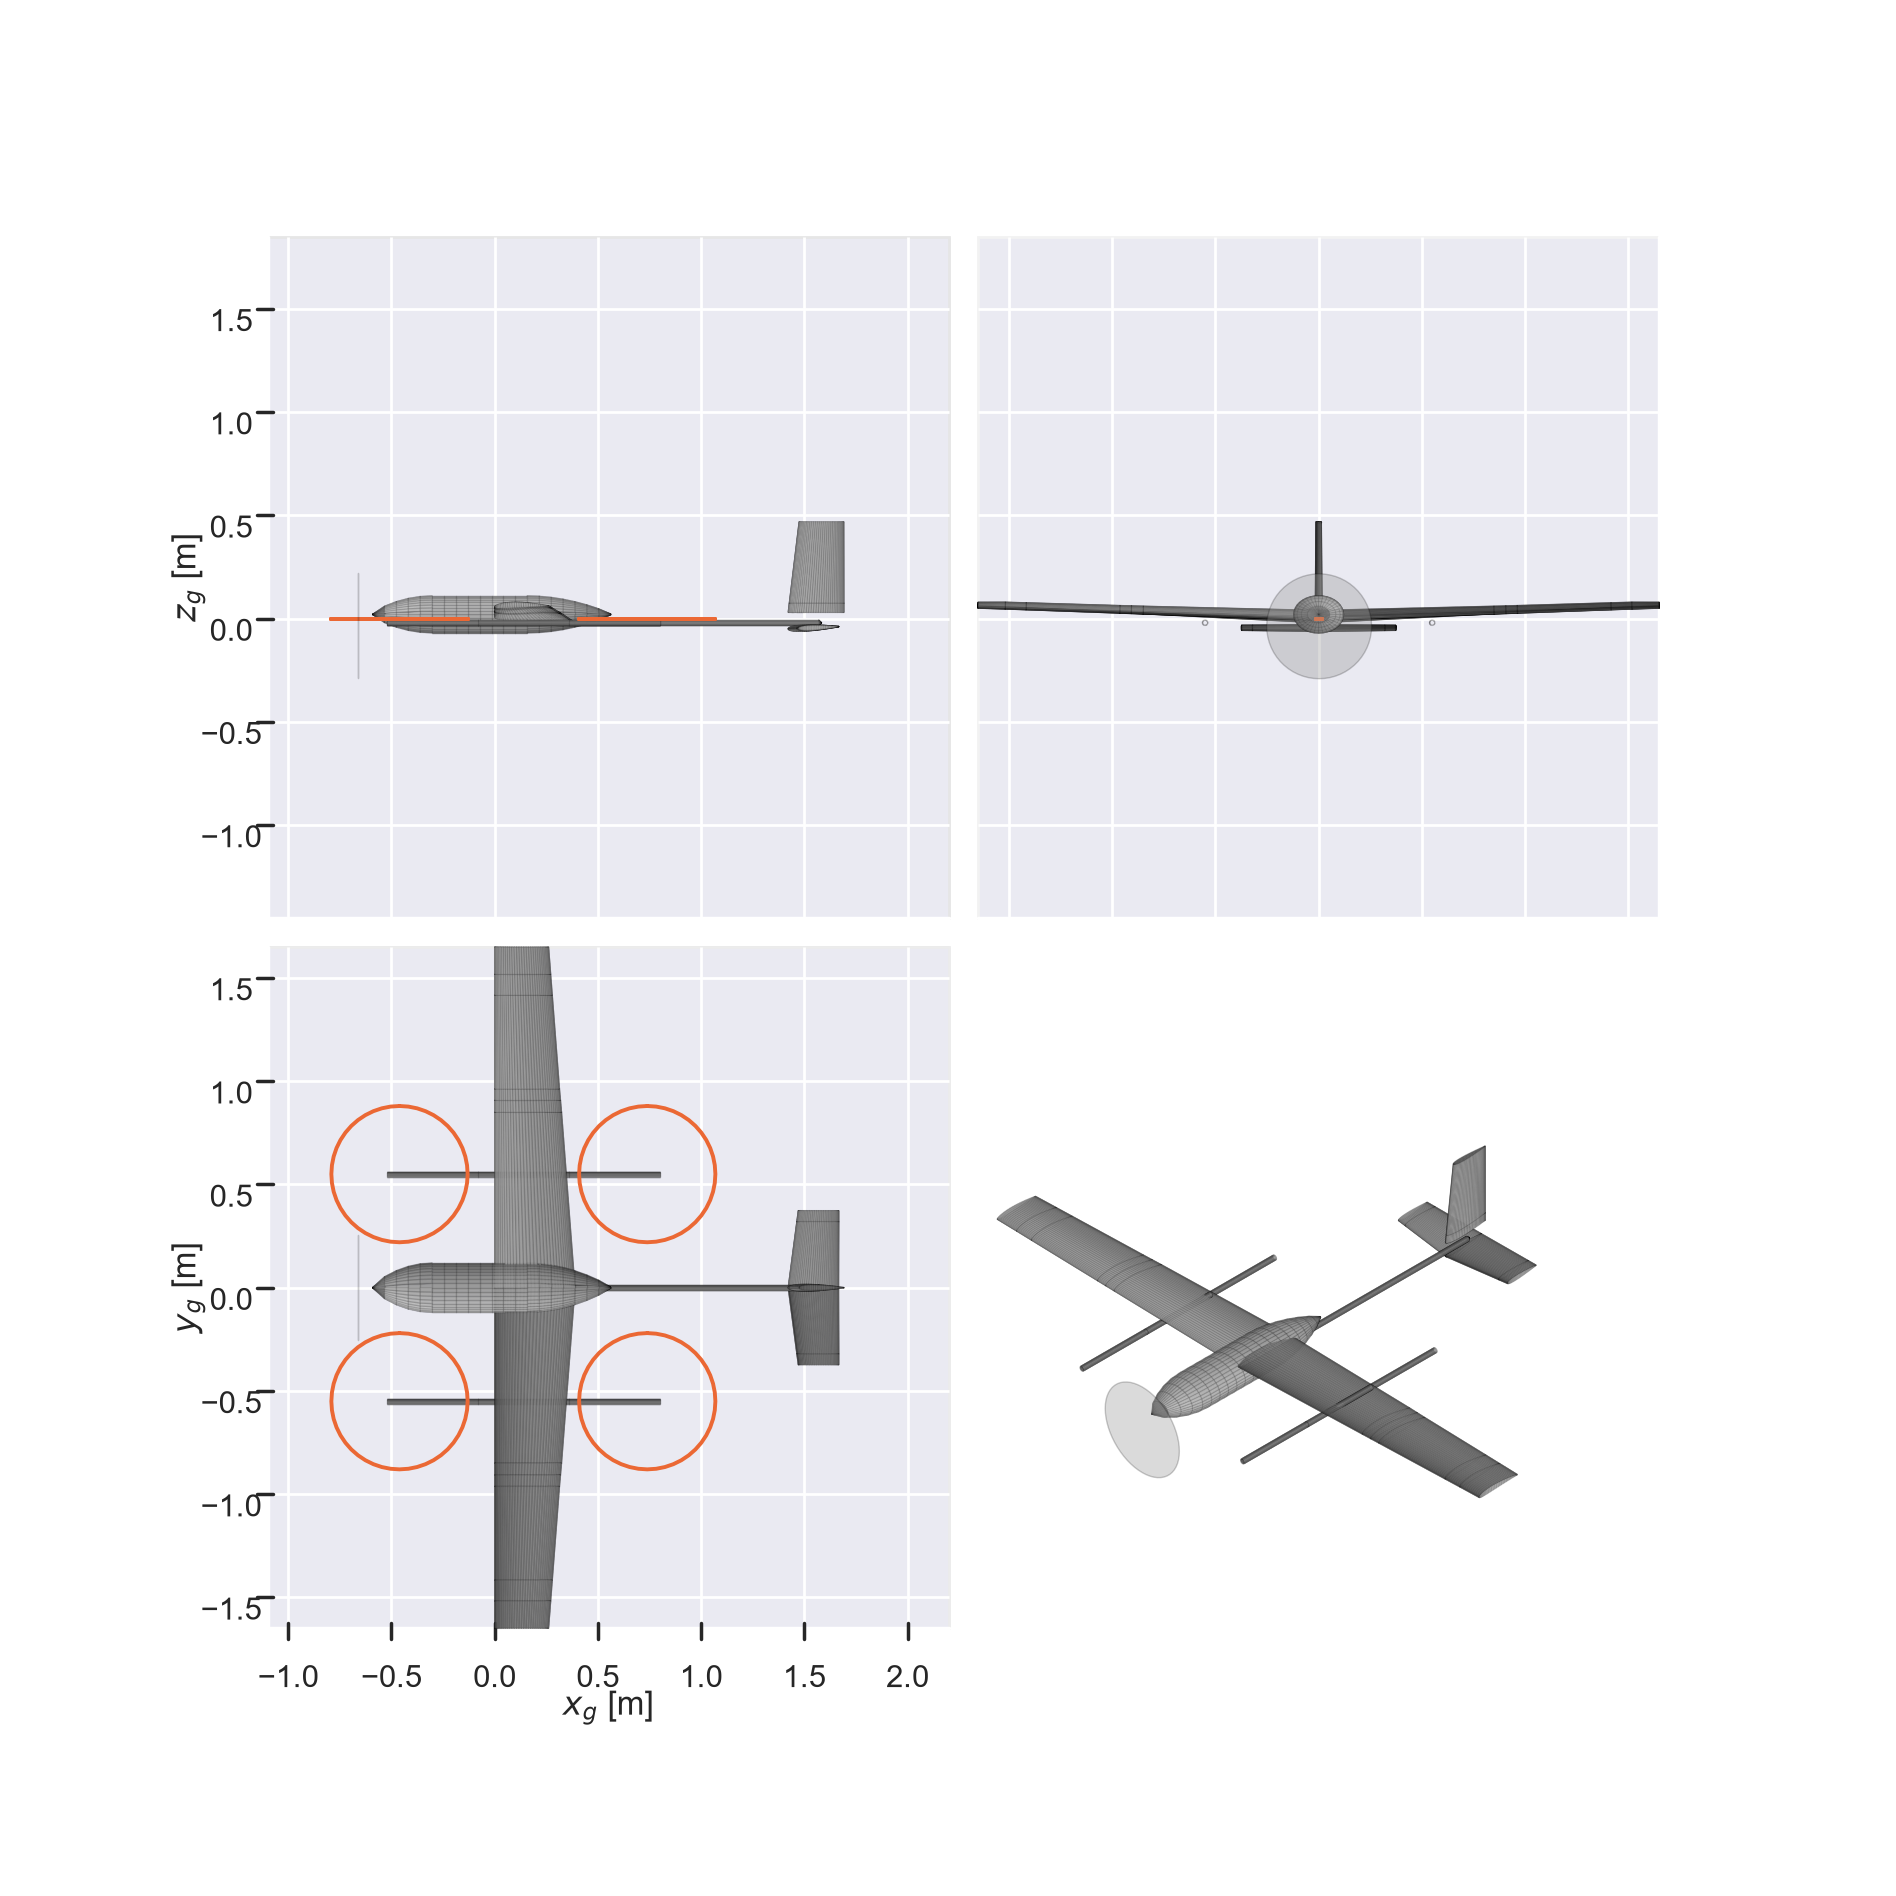

In [12]:
v = res.design
plot.sizing_schematic(model, res);
plot.three_view(model, v);

## 6. Limits


,value,bound,cost [Wh per unit]
limit,,,
motor_current_front,53.997,53.997,0.17951
motor_current_rear,53.997,53.997,0.16932
control_yaw_rad_s2,1.5,1.5,0.9614


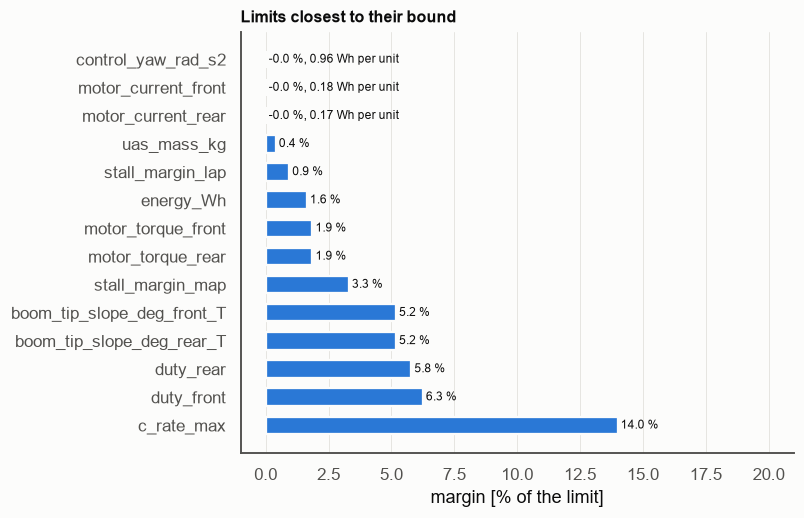

In [13]:
# A limit with a margin of 0 is active. Cost: the Wh that one more unit of the limit costs (IPOPT multiplier).
plot.margin_chart(res);
act = pd.DataFrame([{"limit": k, "value": c["value"], "bound": c["hi"] if c["hi"] is not None else c["lo"], "cost [Wh per unit]": c["cost_Wh_per_unit"]}
                    for k, c in res.enabled().items() if c["margin"] < 1e-3]).set_index("limit")
act

In [14]:
tube = {k: min(c["margin"] for kk, c in res.enabled().items() if kk.startswith(k)) for k in ("boom_stress", "boom_buckling", "boom_tip_slope")}
print({k: f"{100 * v:.1f} %" for k, v in tube.items()})

{'boom_stress': '68.9 %', 'boom_buckling': '95.2 %', 'boom_tip_slope': '5.2 %'}


## 7. Mass and energy


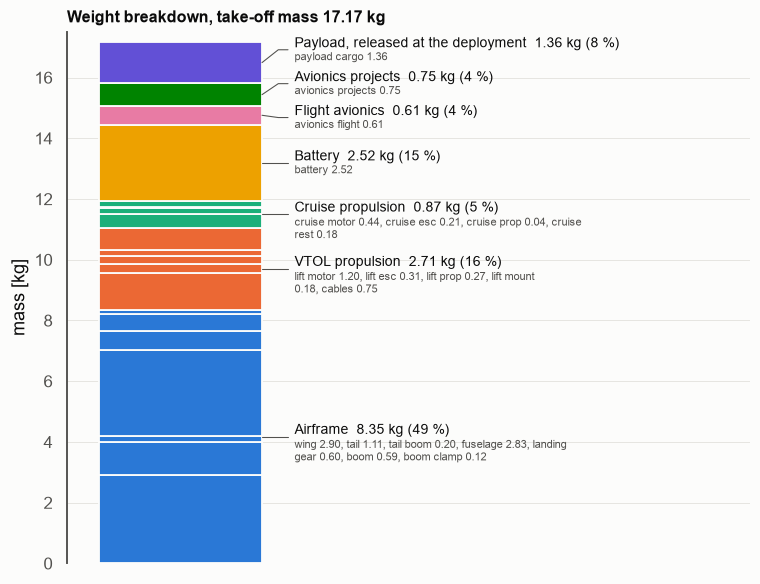

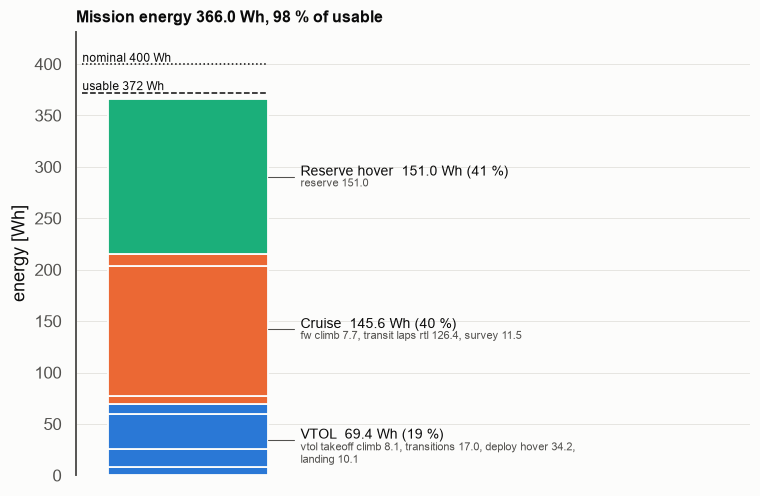

In [15]:
plot.weight_chart(res);
plot.energy_chart(res);

### 7.1 Motor and ESC mass against maker data


motor: m = 188 q^0.690 g, 103 rows, log RMS 0.212
ESC:   m = 7.38 I^0.662 g, 101 rows, log RMS 0.576


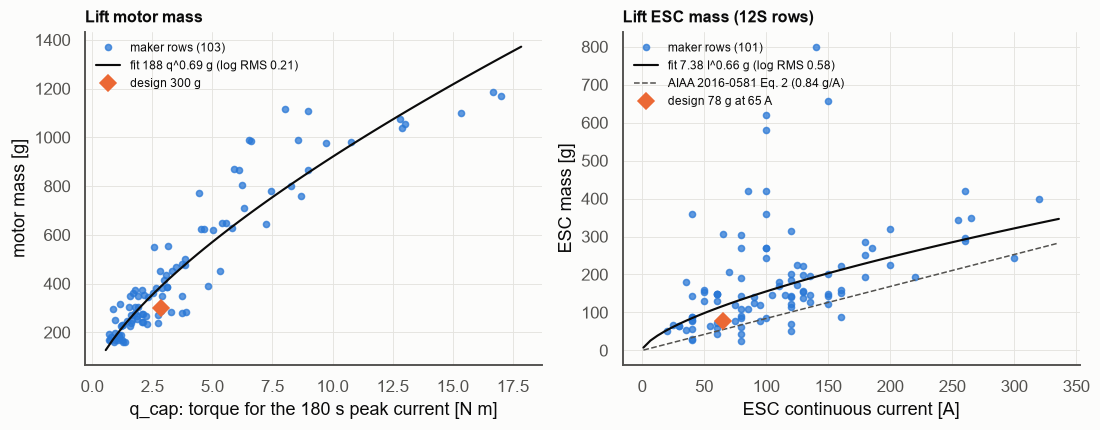

In [16]:
# Motor mass: a power law of q_cap. ESC mass: a power law of the continuous current (12S rows).
# AIAA 2016-0581 Eq. 2 is drawn for comparison. The diamond is the design (fixed parts: the maker mass).
plot.fit_chart(model, res);
from aeroplan.aerosandbox.component import esc_model, motor_model
mm, em = motor_model(model.c["motor"]), esc_model(model.c["esc"], int(model.c["battery"]["cells_s"]))
print(f"motor: m = {math.exp(mm.mass_fit[0]):.0f} q^{mm.mass_fit[1]:.3f} g, {mm.n} rows, log RMS {mm.mass_rms:.3f}")
print(f"ESC:   m = {math.exp(em.fit[0]):.2f} I^{em.fit[1]:.3f} g, {em.n} rows, log RMS {em.rms:.3f}")

### 7.2 Battery through the mission


In [17]:
b = res["battery"]
print(f"OCV fit: {b['ocv_fit']['rows']} rows, RMS {1000 * b['ocv_fit']['rms_V']:.1f} mV. "
      f"Lowest SOC {b['soc_min']:.2f}: pack OCV {b['V_oc_min_V']:.1f} V")
print(f"{'segment':20s} {'SOC end':>8s} {'V end [V]':>10s} {'I end [A]':>10s}")
for k, s in b["soc_end"].items():
    print(f"{k:20s} {s:8.3f} {b['V_end_V'][k]:10.1f} {b['I_end_A'][k]:10.1f}")
print(f"MAX at the lowest SOC: {res['V_bus_max_V']:.1f} V, {res['I_battery_max_A']:.0f} A")

OCV fit: 10 rows, RMS 1.2 mV. Lowest SOC 0.10: pack OCV 42.5 V
segment               SOC end  V end [V]  I end [A]
vtol_takeoff_climb      0.982       48.0       49.4
transitions             0.943       47.7       41.8
fw_climb                0.926       48.0       23.5
transit_laps_rtl        0.629       45.8        7.5
survey                  0.601       45.6        8.0
deploy_hover            0.518       44.1       45.1
landing                 0.493       44.2       39.8
reserve                 0.116       41.4       42.6
MAX at the lowest SOC: 36.7 V, 194 A


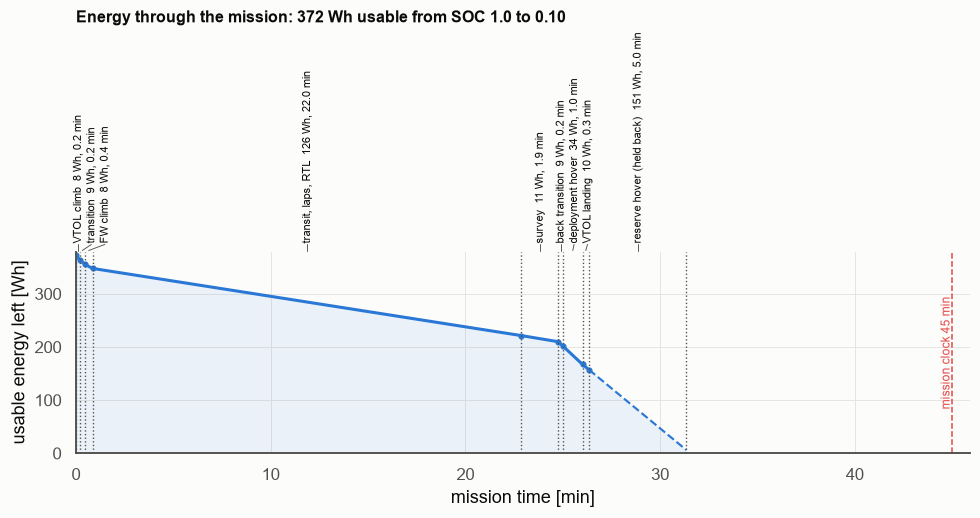

In [18]:
# Usable Wh left above the SOC floor. The transitions segment splits in two halves. Dashed: the reserve, held back.
plot.energy_timeline(res);


## 8. Lift blade against Jung et al. 2021


{'c_max_m': 0.0746, 'c_max_fit_m': 0.064, 'c_max_ratio': 1.167, 'r_at_c_max': 0.355, 'reference': 'Tmotor_29'}


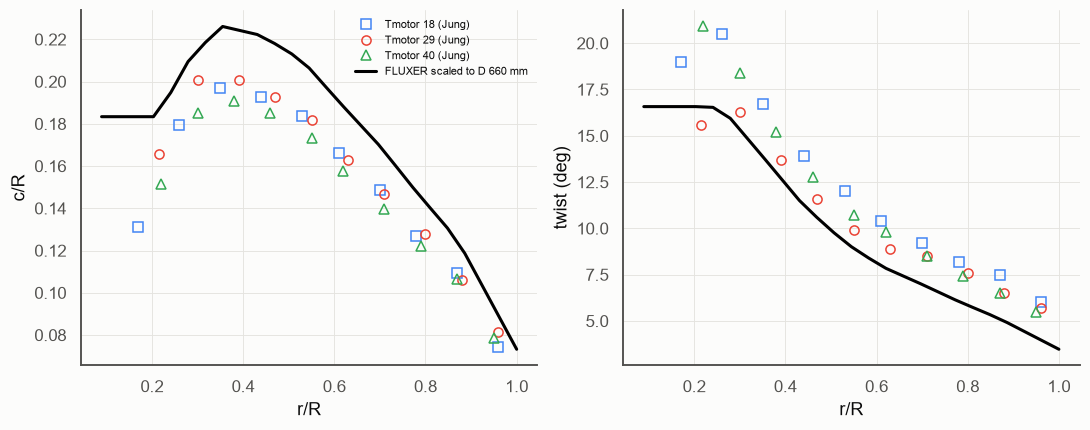

In [19]:
# Jung et al. 2021 (Unmanned Systems 9(4) 321-332, CC BY 4.0): T-motor chord and twist, data/jung2021_blades.csv.
# c_max = 0.0932 D + 2.418 mm (Fig. 10). The blade is a fitted model, not measured geometry.
from aeroplan.aerosandbox.component import jung_compare, jung_plot, scaled_blade
b = scaled_blade(model.c["rotor"], d["scale"])
chk_blade = jung_compare(b["r_over_R"], b["c_m"], b["beta_rad"], b["D_m"])
print({k: round(v, 4) if isinstance(v, float) else v for k, v in chk_blade.items() if k != "rows"})
fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 4))
jung_plot(a1, a2, b["r_over_R"], b["c_m"], b["beta_rad"], b["D_m"], f"FLUXER scaled to D {b['D_m'] * 1000:.0f} mm")
fig.tight_layout();

## 9. Boom vibration


f1 = 18.8 Hz crosses 1P at 1130 rpm = 35 % of the hover speed
f1 Rayleigh 18.83 Hz, f1 exact 18.67 Hz (tip rotary inertia 1.44 g m2)
f2 = 211 Hz (without the tip rotary inertia 336 Hz)
f2 has no 1P crossing up to full throttle (4843 rpm, 1P = 81 Hz)
f2 has no 2P crossing up to full throttle (4843 rpm, 2P = 161 Hz)


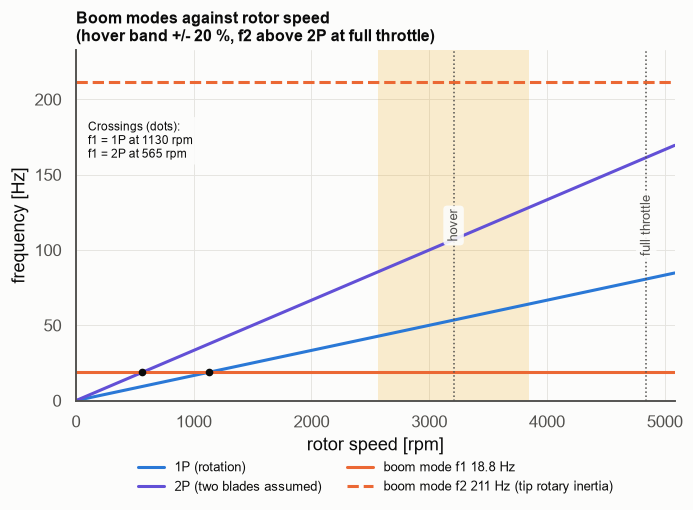

In [20]:
# f1: a cantilever from the clamp with the rotor mass at the tip. The rotors pass the f1 x 1P crossing in spin-up.
# f2: Tube.modes_hz with the tip rotary inertia (estimate). No gyroscopic coupling. f2 is a check, not a limit.
plot.frequency_chart(res);
rpm_h = res["rotors"]["H_TO_f"]["rpm"]
rpm_max = max(res["rotors"]["MAX_f"]["rpm"], res["rotors"]["MAX_r"]["rpm"])
rpm_cross = res["f1_Hz"] * 60
print(f"f1 = {res['f1_Hz']:.1f} Hz crosses 1P at {rpm_cross:.0f} rpm = {100 * rpm_cross / rpm_h:.0f} % of the hover speed")
print(f"f1 Rayleigh {res['f1_Hz']:.2f} Hz, f1 exact {res['f1_exact_Hz']:.2f} Hz (tip rotary inertia {res['boom_J_tip_kg_m2'] * 1e3:.2f} g m2)")
print(f"f2 = {res['f2_Hz']:.0f} Hz (without the tip rotary inertia {res['f2_no_J_Hz']:.0f} Hz)")
for k in (1, 2):
    rpm_x = 60 * res["f2_Hz"] / k
    
    print(f"f2 crosses {k}P at {rpm_x:.0f} rpm" if rpm_x <= rpm_max else
          f"f2 has no {k}P crossing up to full throttle ({rpm_max:.0f} rpm, {k}P = {k * rpm_max / 60:.0f} Hz)")

## 10. Checks

In [21]:
# Hand check: tube mass = density x area x length. f1: Rayleigh, tip mass + 0.236 of the arm mass.
mat, bm = model.c["boom_material"], model.c["boom"]
r_o, t, a = d["r_boom"], d["t_boom"], d["a"]
L = 2 * a + 2 * bm["overhang_m"]
A = math.pi * (r_o**2 - (r_o - t) ** 2)
I = math.pi / 4 * (r_o**4 - (r_o - t) ** 4)
m_each = mat["density_kg_m3"] * A * L
m_tip = n["m_motor"] + n["m_prop"] + n["m_esc"] + model.c["motor"]["mount_kg"]
f1 = math.sqrt(3 * mat["E_Pa"] * I / (a**3 * (m_tip + 0.236 * m_each * a / L))) / (2 * math.pi)
print(f"tube mass each: by hand {1000 * m_each:.2f} g, solver {500 * n['m_boom']:.2f} g")
print(f"f1: by hand {f1:.3f} Hz, solver {res['f1_Hz']:.3f} Hz  (EI = {mat['E_Pa'] * I:.0f} N m2, tip mass {m_tip:.3f} kg)")
assert abs(1000 * m_each - 500 * n["m_boom"]) < 1e-6 and abs(f1 - res["f1_Hz"]) < 1e-6

tube mass each: by hand 295.38 g, solver 295.38 g


f1: by hand 18.831 Hz, solver 18.831 Hz  (EI = 527 N m2, tip mass 0.491 kg)


In [22]:
# Every design value fixed at the optimum (only the battery x closes the CG): no limit breaks, the energy stays.
chk = model.copy()
for name, (ck, pk) in DESIGN_VARS.items():
    chk.c[ck].params[pk].value = float(d[name])
back = evaluate(chk, "L4")
print("limits broken:", back.violated() or "none", "| energy difference:", f"{100 * (back.energy_Wh / res.energy_Wh - 1):+.4f} %")
assert not back.violated() and abs(back.energy_Wh / res.energy_Wh - 1) < 1e-3

limits broken: none | energy difference: -0.0000 %


## 11. SUAS 2027 rules


In [23]:
FT, IN = 0.3048, 0.0254                                # m per ft and m per in (exact, NIST SP 811)
cargo_kg, mis = model.c["cargo"]["mass_kg"], model.c["mission"]
uas_kg = res.mass_kg - cargo_kg
E_nom = res["energy_nominal_Wh"]
S = int(model.c["battery"]["cells_s"])
bat = model.c["battery"]
pack_Wh = bat["cal_cells_s"] * bat["cell_nominal_V"] * bat["cal_capacity_Ah"]
n_packs = round(d["cap_Ah"] / bat["cal_capacity_Ah"]) * (S // int(bat["cal_cells_s"]))
fz = model.c["fuselage"]
W, H, ne = fz["width_m"], fz["height_m"], fz["superellipse_n"]


def box_fits(w, h):                                    # a w x h box section inside the superellipse section (corner test)
    return (w / W) ** ne + (h / H) ** ne <= 1.0


box = (11 * IN, 9 * IN, 4 * IN)
sections = [(box[i], box[j]) for i in range(3) for j in range(3) if i != j]
fit_sections = [f"{1000 * w:.0f} x {1000 * h:.0f} mm" for w, h in sections if box_fits(w, h)]
clock = res.constraints["mission_clock_s"]
ca = model.c["cruise_aero"]
r_turn = n["V_map"] ** 2 / (9.80665 * math.tan(math.radians(mis["survey_turn_bank_deg"])))
rows = [
    ("UAS weight, no delivery object (p. 16)", f"{uas_kg:.2f} kg ({uas_kg / LB:.1f} lb)", "35 lb or less", uas_kg <= 35 * LB + 1e-6),
    ("Full weight points (p. 16)", f"{uas_kg / LB:.1f} lb", "10 lb or less", uas_kg <= 10 * LB),
    ("Battery packs of 100 Wh or less (p. 16)", f"{n_packs} x 6S {bat['cal_capacity_Ah']} Ah, {pack_Wh:.1f} Wh each, {n_packs * pack_Wh:.0f} Wh", "100 Wh or less each", pack_Wh <= 100.0),
    ("Delivery height (p. 18)", f"{mis['climb_height_m']:.0f} m ({mis['climb_height_m'] / FT:.0f} ft) cruise height", "150 ft AGL or more",
     mis["climb_height_m"] >= 150 * FT),
    ("Mission clock (p. 14, p. 17)", f"{clock['value'] / 60:.1f} min (ground time {mis['ground_time_s'] / 60:.1f} min, stand-in)",
     f"{clock['hi'] / 60:.0f} min", clock["value"] <= clock["hi"] + 1e-6),
    ("Lap length (p. 14)", f"{mis['lap_length_m']:.0f} m ({mis['lap_length_m'] / 1609.344:.2f} mi)", "about 2 mi each", True),
    ("Delivery object box in the fuselage section", ", ".join(fit_sections) or "no orientation fits",
     f"11 x 9 x 4 in inside {1000 * W:.0f} x {1000 * H:.0f} mm, n = {ne}", bool(fit_sections)),
    ("Survey turn radius at the survey speed", f"{r_turn:.0f} m at {n['V_map']:.1f} m/s, {mis['survey_turn_bank_deg']:.0f} deg bank",
     f"map_turn_radius_m = {ca['map_turn_radius_m']:.0f} m (stand-in)", r_turn <= ca["map_turn_radius_m"] * 1.05),
]
rules = pd.DataFrame(rows, columns=["rule", "value", "limit", "ok"]).set_index("rule")
rules["state"] = rules.pop("ok").map({True: "ok", False: "FAIL"})
rules


,value,limit,state
rule,,,
"UAS weight, no delivery object (p. 16)",15.81 kg (34.9 lb),35 lb or less,ok
Full weight points (p. 16),34.9 lb,10 lb or less,FAIL
Battery packs of 100 Wh or less (p. 16),"4 x 6S 4.5 Ah, 99.9 Wh each, 400 Wh",100 Wh or less each,ok
Delivery height (p. 18),93 m (305 ft) cruise height,150 ft AGL or more,ok
"Mission clock (p. 14, p. 17)","26.4 min (ground time 0.0 min, stand-in)",45 min,ok
Lap length (p. 14),3370 m (2.09 mi),about 2 mi each,ok
Delivery object box in the fuselage section,no orientation fits,"11 x 9 x 4 in inside 240 x 180 mm, n = 2.5",FAIL
Survey turn radius at the survey speed,"66 m at 19.3 m/s, 30 deg bank",map_turn_radius_m = 40 m (stand-in),FAIL


## 12. Save


In [24]:
# settings/rosella.json: every param with units and source, and the result.
model.result_summary = res.compact()
path = model.save()
res.save(REPO_ROOT / "work" / "aerosandbox" / "rosella" / "sizing" / "best.json")
print(path.relative_to(REPO_ROOT), f"{path.stat().st_size / 1024:.0f} kB")

aeroplan\aerosandbox\settings\rosella.json 54 kB


## 13. Window


In [25]:
# Live notebook only. Evaluate keeps every param fixed. Optimise frees the rows marked free.
from aeroplan.aerosandbox.window import Window
win = Window(model, "L4").show()